In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
deviation_df = pd.read_csv("patient_level_deviations.csv")

deviation_summary = pd.read_csv("deviation_summary.csv")

print("Patient-level records:", len(deviation_df))

print("\nPatient-level deviation data:")
display(deviation_df.head(10))

print("\nDeviation summary:")
display(deviation_summary.head(10))

Patient-level records: 5000

Patient-level deviation data:


,case_id,log_deviation_count,model_deviation_count,total_deviations,log_deviations,missing_model_activities
0,P00001,0,0,0,NaN,NaN
1,P00002,1,1,2,X-Ray,Treatment
2,P00003,0,1,1,NaN,Treatment
3,P00004,2,0,2,"Return to Triage, Triage",NaN
4,P00005,0,0,0,NaN,NaN
5,P00006,0,0,0,NaN,NaN
6,P00007,0,1,1,NaN,Treatment
7,P00008,0,1,1,NaN,Treatment
8,P00009,0,0,0,NaN,NaN
9,P00010,0,1,1,NaN,Treatment



Deviation summary:


,log_deviations,missing_model_activities,patient_count
0,NaN,Treatment,2574
1,NaN,NaN,1044
2,"Return to Triage, Triage",Treatment,625
3,"Return to Triage, Triage",NaN,345
4,X-Ray,Treatment,241
5,"Triage, X-Ray, Return to Triage",Treatment,171


In [4]:
total_cases = len(deviation_df)

deviated_cases = (
    deviation_df["total_deviations"] > 0
).sum()

compliant_cases = total_cases - deviated_cases

deviation_rate = round(
    (deviated_cases / total_cases) * 100, 2
)

compliance_rate = round(
    (compliant_cases / total_cases) * 100, 2
)

print("CARE­FLOW CONFORMANCE RESULTS")
print("--------------------------------")
print("Total patient cases:", total_cases)
print("Cases with detected deviations:", deviated_cases)
print("Cases without detected deviations:", compliant_cases)
print("Deviation rate:", deviation_rate, "%")
print("No-detected-deviation rate:", compliance_rate, "%")

CARE­FLOW CONFORMANCE RESULTS
--------------------------------
Total patient cases: 5000
Cases with detected deviations: 3956
Cases without detected deviations: 1044
Deviation rate: 79.12 %
No-detected-deviation rate: 20.88 %


In [5]:
# Alignment fitness results from Part 4

alignment_average_fitness = 0.8848767909867811
alignment_log_fitness = 0.8809347550671689
alignment_fitting_traces = 20.88

# Token-based replay fitness results from Part 4

token_average_fitness = 0.8531504761904762
token_log_fitness = 0.8632916244558224
token_fitting_traces = 20.88

print("ALIGNMENT FITNESS")
print("-----------------")
print("Average fitness:", alignment_average_fitness)
print("Log fitness:", alignment_log_fitness)
print("Fitting traces:", alignment_fitting_traces, "%")

print("\nTOKEN-BASED REPLAY FITNESS")
print("-------------------------")
print("Average trace fitness:", token_average_fitness)
print("Log fitness:", token_log_fitness)
print("Fitting traces:", token_fitting_traces, "%")

ALIGNMENT FITNESS
-----------------
Average fitness: 0.8848767909867811
Log fitness: 0.8809347550671689
Fitting traces: 20.88 %

TOKEN-BASED REPLAY FITNESS
-------------------------
Average trace fitness: 0.8531504761904762
Log fitness: 0.8632916244558224
Fitting traces: 20.88 %


In [6]:
print("TOP 10 DEVIATION PATTERNS")

display(deviation_summary.head(10))

TOP 10 DEVIATION PATTERNS


,log_deviations,missing_model_activities,patient_count
0,NaN,Treatment,2574
1,NaN,NaN,1044
2,"Return to Triage, Triage",Treatment,625
3,"Return to Triage, Triage",NaN,345
4,X-Ray,Treatment,241
5,"Triage, X-Ray, Return to Triage",Treatment,171


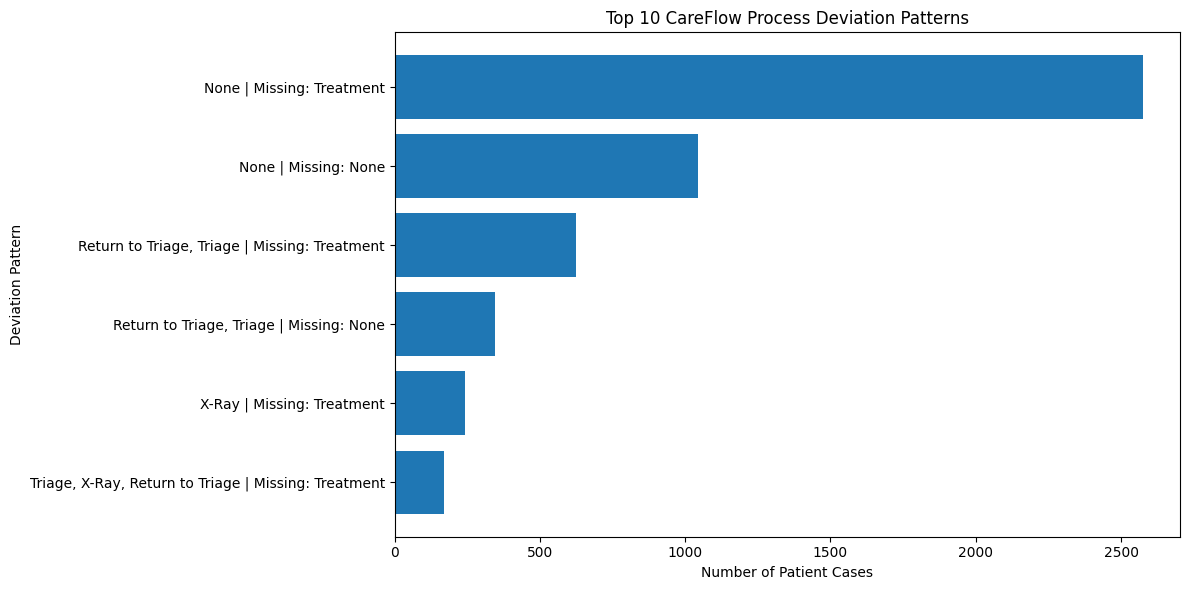

In [7]:
top_deviations = deviation_summary.head(10).copy()

top_deviations["pattern"] = (
    top_deviations["log_deviations"].fillna("None")
    + " | Missing: "
    + top_deviations["missing_model_activities"].fillna("None")
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_deviations["pattern"],
    top_deviations["patient_count"]
)

plt.xlabel("Number of Patient Cases")
plt.ylabel("Deviation Pattern")
plt.title("Top 10 CareFlow Process Deviation Patterns")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "top_deviation_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

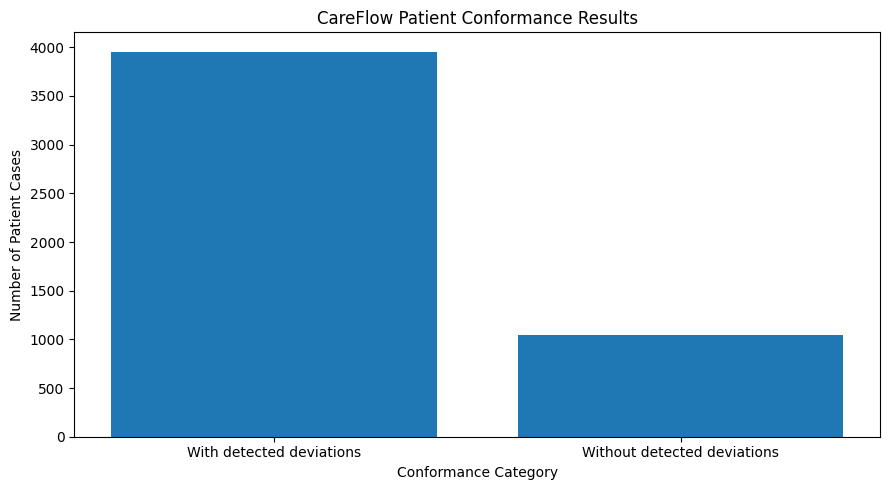

In [8]:
labels = [
    "With detected deviations",
    "Without detected deviations"
]

values = [
    deviated_cases,
    compliant_cases
]

plt.figure(figsize=(9, 5))

plt.bar(labels, values)

plt.title("CareFlow Patient Conformance Results")
plt.xlabel("Conformance Category")
plt.ylabel("Number of Patient Cases")

plt.tight_layout()

plt.savefig(
    "conformance_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
deviation_df.to_csv(
    "patient_level_deviations_final.csv",
    index=False
)

deviation_summary.to_csv(
    "deviation_summary_final.csv",
    index=False
)

print("Final conformance results saved successfully!")

Final conformance results saved successfully!
